# NumPy et SciPy — séance à distance

Ce notebook accompagne les diapositives de la séance. Les exemples et leurs résultats sont enregistrés pour pouvoir relire le cours sans exécuter Python.

**Mode d’emploi :** avancer dans l’ordre, prévoir les résultats, puis exécuter et modifier les cellules ensemble. Pour les exercices, écrire un essai dans la cellule prévue avant de lire la correction suivante. Les cinq compléments de fin de support sont facultatifs pour la séance.

Les données sont fictives. Toutes les équations nécessaires sont données dans les diapositives ; les équations principales sont rappelées ici. Aucun fichier externe n’est nécessaire.

## Préparation

Dans le terminal de l’environnement Python : `python -m pip install numpy scipy matplotlib`.
Dans Jupyter, on peut aussi utiliser une cellule `%pip install numpy scipy matplotlib` si nécessaire.

Les graphiques sont fournis : nous n’étudions pas la syntaxe de Matplotlib pendant cette séance. **Noyau > Redémarrer et tout exécuter** permet de repartir d’un état propre.


## Diapositive 3 — Préparer le notebook

NumPy fournit les tableaux. SciPy fournit les solveurs, l'optimisation, l'intégration et les lois de probabilité. Les versions affichées décrivent l'environnement de cette exécution.

In [1]:
import numpy as np
import scipy
from scipy import linalg, optimize, integrate, stats
print("NumPy", np.__version__, "SciPy", scipy.__version__)

NumPy 2.3.5 SciPy 1.18.1


### Présentation des graphiques (code fourni)
Cette cellule règle uniquement la présentation. Les mêmes couleurs et dimensions sont utilisées dans les figures.

In [2]:
import matplotlib.pyplot as plt
burgundy, ink = "#8C1515", "#2E2D29"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.15,
                     "figure.constrained_layout.use": True})

## Diapositive 5 — Scalaire, vecteur, matrice : des formes différentes

Un vecteur est une suite de composantes, une matrice un tableau à deux axes. `shape` donne la forme, `ndim` le nombre d'axes et `dtype` le type des cases. Pour un tableau numérique, toutes les cases partagent le même type.

In [3]:
x = np.array([10., 20., 30.])
A = np.array([[1., 2.], [3., 4.], [5., 6.]])
print(x.shape, x.ndim)  # (3,) et 1
print(A.shape, A.ndim)  # (3, 2) et 2
print(A.dtype)         # float64

(3,) 1
(3, 2) 2
float64


## Diapositive 6 — Créer les tableaux dont on a besoin

`arange` exclut la borne finale ; `linspace` fixe un nombre de points et inclut les bornes. `zeros` et `ones` remplissent une forme. `reshape` conserve le nombre total de valeurs. Six valeurs peuvent être rangées en `(3, 2)`, mais pas en `(4, 2)`.

In [4]:
print(np.arange(4))        # [0 1 2 3]
print(np.linspace(0, 1, 5)) # [0. 0.25 0.5 0.75 1.]
print(np.zeros((2, 3)))    # 2 lignes, 3 colonnes de zéros
print(np.ones(3))          # [1. 1. 1.]
b = np.arange(6).reshape(2, 3)
print(b)                  # [[0 1 2], [3 4 5]]

[0 1 2 3]
[0.   0.25 0.5  0.75 1.  ]
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1.]
[[0 1 2]
 [3 4 5]]


## Diapositive 7 — Lire, filtrer et copier

Les indices commencent à zéro. `A[i, j]` lit une case, `A[:, j]` une colonne. Une comparaison crée un masque booléen. Une tranche simple partage la mémoire ; `.copy()` crée des données indépendantes.

In [5]:
A = np.array([[10., 20.], [30., 40.], [50., 60.]])
print(A[1, 0])       # 30.0 : ligne 1, colonne 0
print(A[:, 1])       # [20. 40. 60.] : toute la colonne 1
x = np.array([10., 20., 30.])
print(x[x >= 20])    # [20. 30.] : sélection par condition
essai = x[:2].copy()
essai[0] = 999       # x reste inchangé

30.0
[20. 40. 60.]
[20. 30.]


## Diapositive 8 — Les opérations élément par élément

Les opérations portent sur chaque case. `exp(x)` calcule $e^x$ et `log` est le logarithme naturel, inverse de l'exponentielle. Dans les réels, les arguments de `log` doivent être strictement positifs.

In [6]:
x = np.array([1., 2., 3.])
print(x ** 2)       # [1. 4. 9.]
print(2 * x + 1)    # [3. 5. 7.]
print(np.sqrt(x))   # racine carrée de chaque case
print(np.exp(x))    # exponentielle de chaque case
print(np.log(x))    # logarithme naturel, x > 0 ici

[1. 4. 9.]
[3. 5. 7.]
[1.         1.41421356 1.73205081]
[ 2.71828183  7.3890561  20.08553692]
[0.         0.69314718 1.09861229]


## Diapositive 9 — La vectorisation

Les deux versions réalisent le même calcul. NumPy exécute les opérations numériques dans du code compilé. Traiter n valeurs reste un travail en O(n). `np.vectorize` n'est pas une promesse d'accélération : cette fonction de commodité appelle essentiellement une boucle Python.

In [7]:
valeurs = [1., 2., 3.]
resultat_python = []
for valeur in valeurs:
    resultat_python.append(2 * valeur + 1)

x = np.array(valeurs)
resultat_numpy = 2 * x + 1
print(resultat_python, resultat_numpy)

[3.0, 5.0, 7.0] [3. 5. 7.]


## Diapositive 10 — Exercice : convertir des mesures

**À essayer avant de continuer.** Le capteur donne des valeurs brutes $r$ et la conversion est $T=0{,}5r-10$ en °C. Prévoir les quatre températures, calculer le tableau puis sélectionner les valeurs strictement supérieures à 15 °C. Écrire les étapes en une phrase avant le code.

In [8]:
brut = np.array([20., 40., 60., 80.])

### À essayer avant la correction
Calculer les températures puis extraire celles qui dépassent 15 °C.

In [9]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 11 — Résultat : quatre conversions en une expression

Résultat attendu : `[0., 10., 20., 30.]`, puis `[20., 30.]`. `allclose` compare les valeurs avec une tolérance. Modifier 0,5 en 0,6 doit donner `[2., 14., 26., 38.]` ; adapter aussi la valeur attendue dans `assert`.

In [10]:
temperature = 0.5 * brut - 10
chaudes = temperature[temperature > 15]
print(temperature)  # [ 0. 10. 20. 30.]
print(chaudes)      # [20. 30.]
assert np.allclose(temperature, [0, 10, 20, 30])

[ 0. 10. 20. 30.]
[20. 30.]


## Diapositive 12 — Vitesse et mémoire : ce qu’il faut vérifier

Le chronomètre répète trois mesures de dix calculs ; on affiche le meilleur temps par calcul. La conversion de liste en tableau reste hors mesure. Les temps changent selon la machine et la taille. Les deux sorties sont équivalentes, mais leur représentation en mémoire diffère.

In [11]:
import timeit
x_test = np.linspace(0, 100, 100_000)
liste_test = x_test.tolist()
tp = timeit.repeat("[0.5*v-10 for v in liste_test]",
                  globals=globals(), number=10, repeat=3)
tn = timeit.repeat("0.5*x_test-10", globals=globals(),
                  number=10, repeat=3)
print(min(tp) / 10, min(tn) / 10)  # secondes par calcul

0.0019440124975517391 2.3229204816743732e-05


## Diapositive 13 — Les axes donnent un sens aux résumés

Une ligne représente une observation, une colonne une variable. `axis=0` réduit les observations et garde une valeur par colonne. `axis=1` réduit les variables et garde une valeur par ligne. Une somme de colonnes n'est pertinente que si leurs unités le permettent.

In [12]:
X = np.array([[10., 100.],
              [20., 200.],
              [30., 300.]])
print(X.mean(axis=0))  # [20. 200.] : moyenne par colonne
print(X.sum(axis=1))   # [110. 220. 330.] : somme par ligne
print(X.shape)        # (3, 2)

[ 20. 200.]
[110. 220. 330.]
(3, 2)


## Diapositive 14 — Le broadcasting : associer des formes compatibles

Le broadcasting associe des dimensions égales ou de longueur 1, en partant de la droite. Soustraire une moyenne par colonne associe `(3, 2)` à `(2,)`. Un facteur par ligne demanderait une forme `(3, 1)`.

In [13]:
moyennes = X.mean(axis=0)   # forme (2,)
centre = X - moyennes      # forme (3, 2)
print(centre)

[[ -10. -100.]
 [   0.    0.]
 [  10.  100.]]


## Diapositive 15 — Moyenne, variance et écart-type

Moyenne $\mu=\sum_i x_i/n$, variance $v=\sum_i(x_i-\mu)^2/n$, écart-type $\sigma=\sqrt{v}$. `ddof=0` utilise n au dénominateur. `ddof=1` utilise n−1 pour la variance d'échantillon.

In [14]:
x = np.array([10., 20., 30.])
print(x.mean())       # 20.0
print(x.var(ddof=0))  # environ 66.6667
print(x.std(ddof=0))  # environ 8.1650

20.0
66.66666666666667
8.16496580927726


### À essayer avant la correction
Exercice (diapositive 16) : centrer et réduire chaque colonne de X. Calculer les moyennes et écarts-types par colonne, prévoir leur forme et gérer une colonne constante.

In [15]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 17 — Résultat : centrer et réduire chaque colonne

**Correction de l'exercice de la diapositive 16.** On calcule $Z_{ij}=(X_{ij}-\mu_j)/\sigma_j$. Une colonne constante devient nulle avec notre convention. Pour de nouvelles données, réutiliser les statistiques calculées sur l'entraînement, sans les recalculer sur le test.

In [16]:
mu = X.mean(axis=0)
sigma = X.std(axis=0, ddof=0)
echelle = np.where(sigma == 0, 1., sigma)
Z = (X - mu) / echelle
print(Z)
# [[-1.2247, -1.2247], [0., 0.], [1.2247, 1.2247]] environ
print(Z.mean(axis=0))  # proche de [0., 0.]
print(Z.std(axis=0))   # [1., 1.] ici

[[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]
[0. 0.]
[1. 1.]


## Diapositive 18 — Un produit scalaire est une somme pondérée

Le produit scalaire est une somme de produits : $q\cdot p=\sum_i q_i p_i$. Ici, 2 cahiers à 3 € et 4 stylos à 5 € coûtent 26 €. La norme euclidienne est $\|q\|=\sqrt{q\cdot q}$.

In [17]:
q = np.array([2., 4.])
p = np.array([3., 5.])
print(q * p)         # [ 6. 20.] : produits séparés
print(q @ p)         # 26.0 : somme des produits
print(np.sqrt(q @ q)) # longueur du vecteur, environ 4.4721

[ 6. 20.]
26.0
4.47213595499958


## Diapositive 19 — La multiplication matrice-vecteur

La matrice Q contient une ligne par journée et une colonne par produit. `Q @ p` renvoie une recette par journée. `Q * p` conserve un montant par produit et par journée.

In [18]:
Q = np.array([[2., 4.], [1., 3.], [5., 2.]])
recettes = Q @ p
print(recettes)   # [26. 18. 25.]

[26. 18. 25.]


## Diapositive 20 — Transposer : échanger les lignes et les colonnes

La transposition échange lignes et colonnes. Un vecteur 1D n'a pas d'orientation ligne/colonne : `.T` n'y ajoute pas un axe. Pour une matrice X de forme `(100, 4)` et r de forme `(100,)`, `X.T @ r` a la forme `(4,)`.

In [19]:
print(Q.shape)       # (3, 2)
print(Q.T.shape)     # (2, 3)
print(Q.T)
# [[2. 1. 5.]
#  [4. 3. 2.]]
print(p.shape, p.T.shape)  # (2,) et (2,)
colonne = p.reshape(2, 1)
print(colonne.shape)      # (2, 1)

(3, 2)
(2, 3)
[[2. 1. 5.]
 [4. 3. 2.]]
(2,) (2,)
(2, 1)


## Diapositive 22 — Exercice : retrouver les deux prix

**À essayer.** Les factures donnent $2c+s=11$ et $c+3s=18$. Utiliser `linalg.solve(A_factures, b_factures)`, puis vérifier les deux factures. Le résidu est $A\theta-b$.

In [20]:
A_factures = np.array([[2., 1.], [1., 3.]])
b_factures = np.array([11., 18.])

### À essayer avant la correction
Résoudre les factures et vérifier le résidu.

In [21]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 23 — Résultat : vérifier les deux factures

Prix attendus : 3 € pour le cahier et 5 € pour le stylo. Le résidu peut contenir de minuscules écarts dus aux arrondis. `atol=1e-10, rtol=0` fixe ici une tolérance absolue.

In [22]:
theta_factures = linalg.solve(A_factures, b_factures)
print(theta_factures)                  # [3. 5.]
print(A_factures @ theta_factures)      # [11. 18.]
residu = A_factures @ theta_factures - b_factures
print(residu)                         # proche de [0. 0.]
assert np.allclose(residu, 0, rtol=0, atol=1e-10)

[3. 5.]
[11. 18.]
[-3.55271368e-15  0.00000000e+00]


## Diapositive 25 — Ajuster la droite avec les moindres carrés

On ajuste $\widehat y=b+ax$ aux budgets x et ventes y. La colonne de 1 multiplie b, la colonne x multiplie a ; les coefficients sont dans l'ordre `(b, a)`. `column_stack` assemble ces colonnes. **Application :** appeler `linalg.lstsq(M, y)`, récupérer sa première sortie et prédire les ventes.

In [23]:
x_pub = np.array([0., 1., 2., 3.])
y = np.array([10., 14., 15., 21.])
M = np.column_stack((np.ones(4), x_pub))
print(M)  # [[1. 0.], [1. 1.], [1. 2.], [1. 3.]]

[[1. 0.]
 [1. 1.]
 [1. 2.]
 [1. 3.]]


### À essayer avant la correction
Récupérer les coefficients des moindres carrés et calculer les ventes prédites.

In [24]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 26 — Résultat : une première régression linéaire

La solution minimise la somme des carrés des écarts. La perte affichée est sa moyenne $J=\frac1n\sum_i(\widehat y_i-y_i)^2$. Résultats : $(b,a)=(9{,}9;3{,}4)$ et MSE $1{,}05$. L'ajustement est descriptif ; il ne prouve pas une causalité.

In [25]:
solution = linalg.lstsq(M, y)
theta = solution[0]
y_calcule = M @ theta
mse = ((y_calcule - y) ** 2).mean()
print(theta)       # [9.9 3.4] : constante, puis pente
print(y_calcule)   # [9.9 13.3 16.7 20.1]
print(mse)         # environ 1.05

[9.9 3.4]
[ 9.9 13.3 16.7 20.1]
1.0499999999999985


### La droite et les quatre observations
Graphique fourni pour lire le calcul précédent.

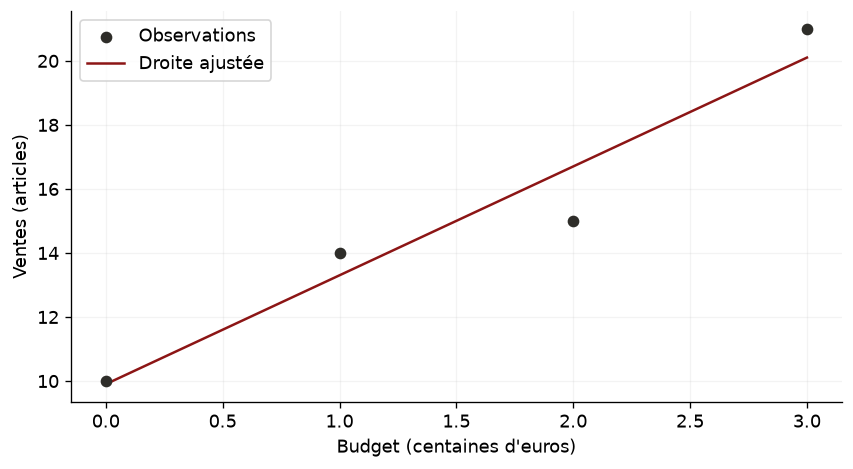

In [26]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(x_pub, y, color=ink, label="Observations", zorder=3)
ax.plot(x_pub, y_calcule, color=burgundy, label="Droite ajustée")
ax.set(xlabel="Budget (centaines d'euros)", ylabel="Ventes (articles)")
ax.legend(); plt.show()

La droite monte de 3,4 articles par centaine d’euros de budget. Les points ne sont pas tous sur la droite : l’erreur moyenne au carré vaut 1,05 sur ces quatre observations fictives.

## Diapositive 28 — Approcher une dérivée avec deux évaluations

La dérivée décrit la pente locale. Pour $f(x)=x^2$, $f'(x)=2x$. L'approximation centrée est $(f(x+h)-f(x-h))/(2h)$. Vérifier 4 en x=2 et 6 en x=3. Un pas trop petit peut amplifier les effets d'arrondi.

In [27]:
def f(x):
    return x ** 2

h = 1e-5
pente_locale = (f(2 + h) - f(2 - h)) / (2 * h)
print(pente_locale)  # proche de 4

4.000000000026205


### Une courbe et sa tangente
Graphique fourni pour lire le calcul précédent.

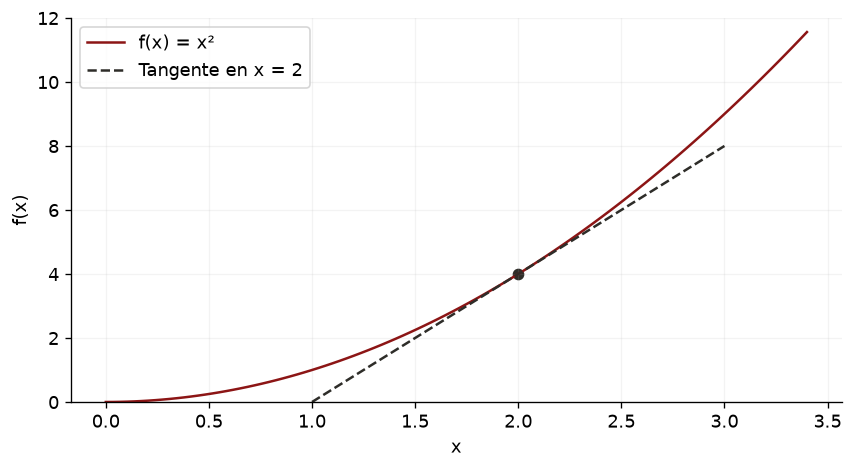

In [28]:
x_grille = np.linspace(0, 3.4, 100)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x_grille, x_grille**2, color=burgundy, label="f(x) = x²")
ax.plot([1, 3], [0, 8], "--", color=ink, label="Tangente en x = 2")
ax.scatter([2], [4], color=ink)
ax.set(xlabel="x", ylabel="f(x)", ylim=(0, 12))
ax.legend(); plt.show()

Au point (2, 4), la tangente a une pente de 4. Elle approche la courbe près de ce point ; elle ne se confond pas avec la parabole sur tout l’intervalle.

### À essayer avant la correction
Exercice (diapositive 30) : écrire trois mises à jour pour J(w)=(w−3)², avec w=0 et eta=0.2. Tracer les variables avant de coder.

In [29]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 31 — Résultat : la perte diminue à chaque pas

**Correction de l'exercice de la diapositive 30.** Pour $J(w)=(w-3)^2$, la dérivée vaut $2(w-3)$. Mettre à jour $w\leftarrow w-\eta J'(w)$ avec $\eta=0{,}2$. Les trois valeurs attendues sont 1,2 ; 1,92 ; 2,352. Un pas de 1,1 ferait diverger cet exemple.

In [30]:
w = 0.0
eta = 0.2
for tour in range(3):
    derivee = 2 * (w - 3)
    w = w - eta * derivee
    print(w, (w - 3) ** 2)

1.2000000000000002 3.2399999999999993
1.9200000000000002 1.1663999999999997
2.3520000000000003 0.4199039999999996


## Diapositive 33 — SciPy peut chercher les paramètres

Le gradient regroupe les dérivées partielles. Pour $r=M\theta-y$ et $J=\frac1n r^Tr$, la formule est $\nabla J=\frac2n M^Tr$. `perte` renvoie un nombre ; `gradient` renvoie une composante par paramètre.

In [31]:
def perte(theta):
    r = M @ theta - y
    return (r ** 2).mean()

def gradient(theta):
    r = M @ theta - y
    return (2 / len(y)) * (M.T @ r)

## Diapositive 34 — Résultat : comparer deux méthodes de résolution

SciPy reçoit les objets fonctions, un point initial et un algorithme. BFGS utilise le gradient mais ne se réduit pas à une descente à pas fixe. Vérifier `success`, lire `message`, puis comparer `x` et `fun` avec la solution des moindres carrés.

In [32]:
resultat = optimize.minimize(perte, x0=np.array([0., 0.]),
                            jac=gradient, method="BFGS")
print(resultat.success, resultat.message)
print(resultat.x)    # proche de [9.9 3.4]
print(resultat.fun)  # proche de 1.05
assert resultat.success
assert np.allclose(resultat.x, theta, atol=1e-6)

True Optimization terminated successfully.
[9.9 3.4]
1.0499999999999983


### Repère de la diapositive 35 : la règle de chaîne
Si $z=f(w)$ puis $L=g(z)$, alors $dL/dw=(dL/dz)(dz/dw)$.
Pour $z=2w+1$ et $L=(z-5)^2$, on trouve $dL/dw=4(z-5)$, donc −8 en w=1.
La rétropropagation applique cette règle aux dépendances d’un réseau.

## Diapositive 37 — Exercice : calculer une distance avec SciPy

**À essayer.** La vitesse $v(t)=2t$ est en m/s. Calculer $\int_0^4 v(t)\,dt$ avec `integrate.quad(vitesse, 0, 4)`. Prévoir l'aire du triangle : 16 m. Refaire entre 0 et 3 : on attend 9 m. Les sorties sont la valeur et une estimation de l'erreur numérique.

In [33]:
def vitesse(t):
    return 2 * t

### À essayer avant la correction
Appeler quad pour calculer les distances entre 0 et 4, puis entre 0 et 3 secondes.

In [34]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 38 — Résultat : 16 mètres, puis 9 mètres

Le résultat vaut 16 m, puis 9 m. L'erreur renvoyée par `quad` concerne le calcul numérique ; elle ne mesure pas une incertitude physique ou statistique.

In [35]:
distance, erreur_numerique = integrate.quad(vitesse, 0, 4)
print(distance, erreur_numerique)  # 16.0 ; erreur très petite
print(integrate.quad(vitesse, 0, 3)[0])  # 9.0

16.0 1.7763568394002505e-13
9.0


### La distance comme aire sous la vitesse
Graphique fourni pour lire le calcul précédent.

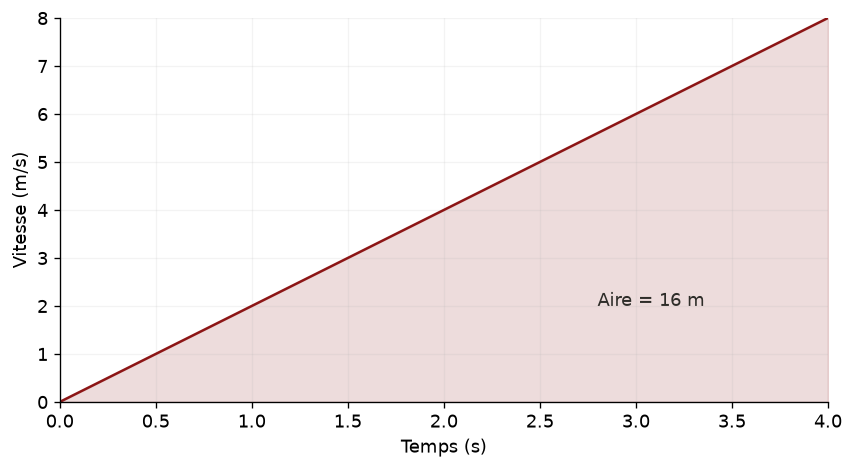

In [36]:
t_grille = np.linspace(0, 4, 100)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t_grille, vitesse(t_grille), color=burgundy)
ax.fill_between(t_grille, 0, vitesse(t_grille), color=burgundy, alpha=0.15)
ax.set(xlabel="Temps (s)", ylabel="Vitesse (m/s)", xlim=(0,4), ylim=(0,8))
ax.text(2.8, 2, "Aire = 16 m", color=ink)
plt.show()

Entre 0 et 4 secondes, l’aire sous la vitesse est celle d’un triangle : 4 × 8 / 2 = 16 mètres. Cette égalité simple contrôle le résultat de l’intégrateur.

## Diapositive 40 — Espérance et variance : pondérer par les probabilités

Le bénéfice G vaut −100, 50 ou 200 € avec probabilités 0,2 ; 0,5 ; 0,3. Les probabilités somment à 1. $\mathbb E[G]=\sum_k p_kg_k$ et $\mathrm{Var}(G)=\sum_k p_k(g_k-\mu)^2$. Attendus : moyenne 65 €, écart-type 105 €.

In [37]:
gains = np.array([-100., 50., 200.])
probabilites = np.array([0.2, 0.5, 0.3])
esperance = probabilites @ gains
variance = probabilites @ ((gains - esperance) ** 2)
print(esperance, np.sqrt(variance))  # 65.0 et 105.0 euros

65.0 105.0


### À essayer avant la correction
Exercice (diapositive 42) : créer une loi binomiale (n=10, p=0.2), puis calculer aucun achat, au moins un achat et au plus deux achats.

In [38]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 43 — Résultat : un événement, une méthode

**Correction de l'exercice de la diapositive 42.** Dix essais indépendants, chacun avec probabilité d'achat p=0,2, donnent un nombre d'achats de loi binomiale. `pmf(k)` vaut $P(K=k)$, `cdf(k)` vaut $P(K\le k)$, `sf(k)` vaut $P(K>k)$. Les trois réponses sont environ 10,74 %, 89,26 % et 67,78 %.

In [39]:
loi_achats = stats.binom(n=10, p=0.2)
print(loi_achats.pmf(0))  # environ 0.1074
print(loi_achats.sf(0))   # environ 0.8926
print(loi_achats.cdf(2))  # environ 0.6778

0.10737418240000011
0.8926258176
0.6777995263999999


### À essayer avant la correction
Exercice (diapositive 46) : pour une normale de moyenne 100 ms et écart-type 15 ms, calculer la probabilité de [85,115] puis le quantile à 95 %.

In [40]:
# Votre essai : écrire les étapes, puis le code.


## Diapositive 47 — Résultat : une probabilité et un seuil

**Correction de l'exercice de la diapositive 46.** Le temps suit, par hypothèse, une normale de moyenne 100 ms et écart-type 15 ms. La probabilité d'un intervalle est une aire, calculée par différence de CDF. `ppf(0.95)` donne le quantile à 95 %. `pdf(t)` donne une densité, pas $P(T=t)$.

In [41]:
loi_temps = stats.norm(loc=100, scale=15)
proba_intervalle = loi_temps.cdf(115) - loi_temps.cdf(85)
seuil_95 = loi_temps.ppf(0.95)
print(proba_intervalle)  # environ 0.6827
print(seuil_95)          # environ 124.67 ms
print(loi_temps.sf(seuil_95))  # environ 0.05

0.6826894921370859
124.67280440427209
0.05000000000000001


### Une aire de probabilité
Graphique fourni pour lire le calcul précédent.

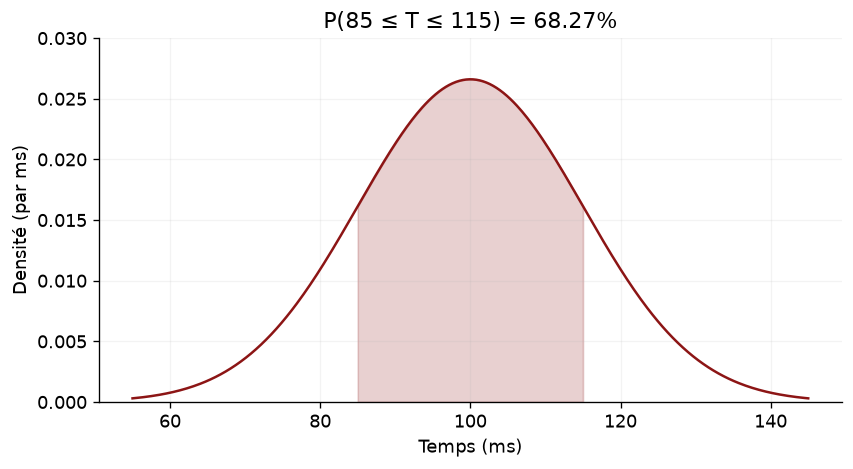

In [42]:
t_grille = np.linspace(55, 145, 400)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t_grille, loi_temps.pdf(t_grille), color=burgundy)
zone = (t_grille >= 85) & (t_grille <= 115)
ax.fill_between(t_grille, 0, loi_temps.pdf(t_grille), where=zone,
                color=burgundy, alpha=0.2)
ax.set(xlabel="Temps (ms)", ylabel="Densité (par ms)", ylim=(0,.03))
ax.set_title(f"P(85 ≤ T ≤ 115) = {proba_intervalle:.2%}")
plt.show()

La zone colorée représente environ 68,27 % des temps selon le modèle normal choisi. L’axe vertical mesure une densité par milliseconde ; c’est l’aire qui donne une probabilité.

## Diapositive 48 — Simuler pour retrouver une probabilité

`rvs` tire des valeurs de la loi à l'aide du générateur fourni. `&` combine des masques case par case, avec parenthèses. La moyenne du masque estime la probabilité ; elle fluctue autour de la valeur théorique de 0,6827.

In [43]:
rng = np.random.default_rng(2026)
temps = loi_temps.rvs(size=10_000, random_state=rng)
dans_intervalle = (temps >= 85) & (temps <= 115)
print(temps.mean(), temps.std())
print(dans_intervalle.mean())  # proche de 0.6827

99.96891034049938 15.084318398278912
0.6754


## Diapositive 50 — Un premier calcul de neurone

Un neurone calcule $z=Xw+b$, puis une activation. Ici, $b=0$ et $\sigma(z)=1/(1+e^{-z})$. Les poids sont arbitraires : les sorties ne sont pas encore des probabilités validées. Nous n'avons entraîné aucun réseau.

In [44]:
X_neurone = np.array([[1., 0.], [0., 1.], [1., 1.]])
poids = np.array([1., -1.])
z = X_neurone @ poids
activation = 1 / (1 + np.exp(-z))
print(z)           # [ 1. -1.  0.]
print(activation)  # environ [0.7311 0.2689 0.5]

[ 1. -1.  0.]
[0.73105858 0.26894142 0.5       ]


## Diapositive 55 — Complément : Bayes et les fausses alertes

**Complément.** Pour un défaut D et une alerte A, la probabilité cherchée est $P(D\mid A)$, pas $P(A\mid D)$. La formule de Bayes tient compte des défauts rares et des fausses alertes. Résultat : environ 16,10 % des alertes correspondent à un défaut.

In [45]:
p_defaut_sachant_alerte = (0.95 * 0.01) / (
    0.95 * 0.01 + 0.05 * 0.99)
print(p_defaut_sachant_alerte)  # environ 0.1610

0.16101694915254236


## Diapositive 56 — Complément : covariance et corrélation

**Complément.** La covariance d'échantillon utilise $\sum_i(x_i-\bar x)(y_i-\bar y)/(n-1)$. La corrélation la divise par les deux écarts-types. `rowvar=False` signifie une variable par colonne. Corrélation attendue : 0,6.

In [46]:
observations = np.array([[1., 2.], [2., 1.],
                         [3., 4.], [4., 3.]])
C = np.cov(observations, rowvar=False, ddof=1)
print(C)  # environ [[1.6667, 1.], [1., 1.6667]]
print(np.corrcoef(observations, rowvar=False)[0, 1]) # 0.6

[[1.66666667 1.        ]
 [1.         1.66666667]]
0.6000000000000001


## Diapositive 57 — Complément : directions propres et ACP

**Complément.** Un vecteur propre satisfait $Cv=\lambda v$. `eigh` convient à la matrice de covariance réelle symétrique. La valeur propre la plus grande mesure la variance portée par la première direction d'ACP : ici 80 % du total. Les signes des vecteurs peuvent varier sans changer les directions.

In [47]:
valeurs, vecteurs = linalg.eigh(C)
print(valeurs)  # environ [0.6667 2.6667]
direction = vecteurs[:, -1]   # direction de plus forte variance
print(valeurs[-1] / valeurs.sum())  # 0.8
assert np.allclose(C @ direction, valeurs[-1] * direction)

[0.66666667 2.66666667]
0.8


## Diapositive 58 — Complément : l’incertitude sur une moyenne

**Complément.** Pour des observations indépendantes d'une population normale de variance inconnue, l'intervalle de Student est $\bar x\pm t_{0.975,n-1}s/\sqrt n$. La procédure couvre la vraie moyenne dans 95 % des répétitions sous ces hypothèses. Ce n'est pas un intervalle contenant 95 % des observations.

In [48]:
mesures = np.array([98., 102., 99., 101., 100.])
se = stats.sem(mesures)  # écart-type avec ddof=1 / racine de n
intervalle = stats.t.interval(0.95, df=len(mesures)-1,
                             loc=mesures.mean(), scale=se)
print(intervalle)  # environ (98.04, 101.96)

(np.float64(98.03675683852244), np.float64(101.96324316147756))


## Vérifications et repères

- `Q @ p` donne un nombre par ligne ; `Q * p` garde les produits séparés.
- La vectorisation ne rend pas automatiquement le calcul constant en taille.
- Un résidu proche de zéro valide les équations numériques, pas les hypothèses du modèle.
- Le gradient décrit des variations ; le pas détermine la taille des déplacements.
- Une densité n’est pas une probabilité ponctuelle. Les probabilités continues sont des aires.
- Les paramètres d’un modèle s’ajustent sur l’entraînement et se vérifient sur des données distinctes.

## Documentation

[NumPy : bases](https://numpy.org/doc/stable/user/absolute_beginners.html),
[Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html),
[SciPy : algèbre linéaire](https://docs.scipy.org/doc/scipy/reference/linalg.html),
[Optimisation](https://docs.scipy.org/doc/scipy/reference/optimize.html),
[Intégration](https://docs.scipy.org/doc/scipy/reference/integrate.html),
[Statistiques](https://docs.scipy.org/doc/scipy/reference/stats.html).
